# NV-diamond quantum magnetometer: spin physics, optical mounts, and the op-amp readout
### SymPy from the spin-1 Hamiltonian to the transimpedance amplifier's feedback capacitor

**In plain words.** A nitrogen-vacancy (NV) center is a defect in diamond: a nitrogen atom next to
a missing carbon. It behaves like a single trapped electron spin at room temperature. Shine green
light on it and it glows red. Sweep a microwave frequency and the glow **dims** at two frequencies,
whose spacing is set by the magnetic field. That makes the diamond a **magnetometer** read out with
light, a quantum sensor you can build on an optical table.

**The chain covered here:**
1. **Spin physics:** the Hamiltonian, ODMR spectrum, sensitivity, and full vector field.
2. **Optical mounts:** how a mirror mount's screw and thermal drift move the laser spot, and how
   that fakes a magnetic signal.
3. **Op-amp:** the photodiode transimpedance amplifier, with its transfer function, stability,
   and the noise condition for shot-noise-limited readout.

Numbers are typical magnitudes from the literature, not a specific device. Every figure uses the
Okabe–Ito colorblind-safe palette, distinguishes curves by line style as well as color, and has a
printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import nv_magnetometer as nv
from dgs import transimpedance_amplifier as tia
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. The spin-1 Hamiltonian

The NV ground state has spin $S=1$, with sublevels $m_s=+1,0,-1$. First check the spin algebra
$[S_x,S_y]=iS_z$ and $S^2=s(s+1)=2$:

In [2]:
Sx, Sy, Sz = nv.spin1_matrices()
display(Sx, Sy, Sz)
print("[Sx,Sy] - i Sz = 0 and S^2 - 2 = 0:", [m == sp.zeros(3) for m in nv.spin1_algebra_check()])

⎡    √2    ⎤
⎢0   ──  0 ⎥
⎢    2     ⎥
⎢          ⎥
⎢√2      √2⎥
⎢──  0   ──⎥
⎢2       2 ⎥
⎢          ⎥
⎢    √2    ⎥
⎢0   ──  0 ⎥
⎣    2     ⎦

⎡      -√2⋅ⅈ         ⎤
⎢ 0    ──────    0   ⎥
⎢        2           ⎥
⎢                    ⎥
⎢√2⋅ⅈ          -√2⋅ⅈ ⎥
⎢────    0     ──────⎥
⎢ 2              2   ⎥
⎢                    ⎥
⎢       √2⋅ⅈ         ⎥
⎢ 0     ────     0   ⎥
⎣        2           ⎦

⎡1  0  0 ⎤
⎢        ⎥
⎢0  0  0 ⎥
⎢        ⎥
⎣0  0  -1⎦

[Sx,Sy] - i Sz = 0 and S^2 - 2 = 0: [True, True]


Crystal-field splitting $D=2.870$ GHz separates $m_s=0$ from $\pm1$. A field along the NV axis
adds the Zeeman term $\gamma_eB_zS_z$:

In [3]:
H, ev = nv.nv_hamiltonian_symbolic(True)
display(sp.Eq(sp.Symbol("H"), H, evaluate=False))
print("transitions from m_s = 0:", nv.odmr_frequencies_symbolic())
print(f"gamma_e = {nv.GAMMA_E/1e9:.3f} GHz/T = {nv.GAMMA_E/1e10:.2f} MHz/gauss")

    ⎡B_z⋅γₑ + D  0       0     ⎤
    ⎢                          ⎥
H = ⎢    0       0       0     ⎥
    ⎢                          ⎥
    ⎣    0       0  -B_z⋅γₑ + D⎦

transitions from m_s = 0: [-B_z*gamma_e + D, B_z*gamma_e + D]
gamma_e = 28.025 GHz/T = 2.80 MHz/gauss


Two lines at $D\pm\gamma_eB_z$: their **splitting is $2\gamma_eB_z$**. A field
**perpendicular** to the axis only mixes the levels and shifts both lines up slightly, a
second-order effect:

In [4]:
for B in ([0, 0, 1e-3], [1e-3, 0, 0]):
    f = nv.odmr_frequencies(B)
    print(f"B = {np.array(B)*1e3} mT  ->  lines at {f/1e9} GHz, splitting {np.diff(f)[0]/1e6:.3f} MHz")

B = [0. 0. 1.] mT  ->  lines at [2.841975 2.898025] GHz, splitting 56.050 MHz
B = [1. 0. 0.] mT  ->  lines at [2.87027363 2.87054727] GHz, splitting 0.274 MHz


## 2. The ODMR dip and shot-noise sensitivity

Each resonance is a Lorentzian dip of contrast $C$ and full width $\Gamma$. To measure small
changes, park the microwave frequency where the dip is **steepest**. SymPy finds that point and
the slope there:

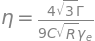

In [5]:
f_star, slope = nv.max_slope_symbolic()
display(sp.Eq(sp.Symbol("f* - f_0"), f_star), sp.Eq(sp.Symbol("max |dS/df|"), slope))
sp.Eq(sp.Symbol("eta"), nv.sensitivity_symbolic())

Photon counting has shot noise $1/\sqrt R$. Dividing it by the slope and by $\gamma_e$ gives
the field resolution $\eta=\dfrac{4\Gamma}{3\sqrt3\,\gamma_eC\sqrt R}$. **Narrow lines, high contrast,
and many photons** all help.

In [6]:
cases = [("single NV", 1e6, 0.30, 1e5), ("ensemble, modest", 8e6, 0.03, 1e11), ("ensemble, bright", 1e6, 0.02, 1e14)]
for name, G, C, R in cases:
    print(f"{name:18s} Gamma = {G/1e6:4.0f} MHz, C = {C:.2f}, R = {R:.0e}/s  ->  eta = {nv.sensitivity(G, C, R):.2e} T/sqrt(Hz)")
print("\nfor scale: Earth's field ~ 5e-5 T; a heartbeat measured at the chest ~ 1e-11 to 1e-10 T")

single NV          Gamma =    1 MHz, C = 0.30, R = 1e+05/s  ->  eta = 2.90e-07 T/sqrt(Hz)
ensemble, modest   Gamma =    8 MHz, C = 0.03, R = 1e+11/s  ->  eta = 2.32e-08 T/sqrt(Hz)
ensemble, bright   Gamma =    1 MHz, C = 0.02, R = 1e+14/s  ->  eta = 1.37e-10 T/sqrt(Hz)

for scale: Earth's field ~ 5e-5 T; a heartbeat measured at the chest ~ 1e-11 to 1e-10 T


## 3. Vector magnetometry: four crystal axes

Diamond hosts NVs along all four $\langle111\rangle$ directions, so an ensemble shows **8 dips**.
Each pair measures $|\mathbf B\cdot\hat n_k|$ on its own axis.

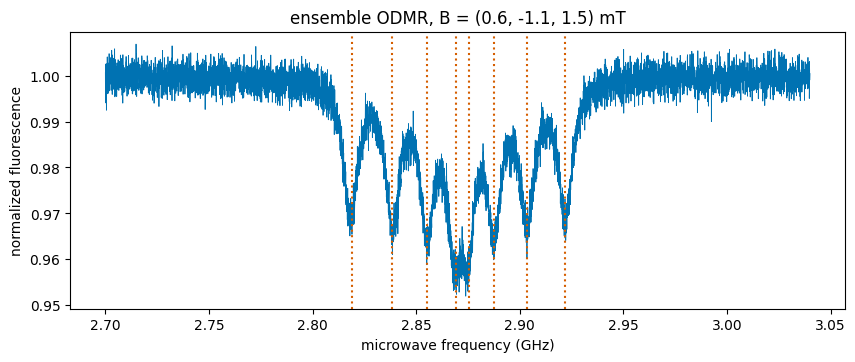

measured |B.n_k| (mT): [1.8355 1.1585 0.5775 0.1065]
true     |B.n_k| (mT): [1.8475 1.1547 0.5774 0.1155]
Figure description: noisy fluorescence spectrum with eight dips symmetric about 2.87 GHz; dotted vertical lines mark the eight detected dip centers.


In [7]:
B = np.array([0.6e-3, -1.1e-3, 1.5e-3])
f = np.linspace(2.70e9, 3.04e9, 6801)
sig = nv.simulate_odmr(B, f, rng=0)
dips = nv.find_dips(f, sig)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(f/1e9, sig, lw=0.6, color=OI[0])
for d in dips: ax.axvline(d/1e9, ls=":", color=OI[1])
ax.set_xlabel("microwave frequency (GHz)"); ax.set_ylabel("normalized fluorescence"); ax.set_title("ensemble ODMR, B = (0.6, -1.1, 1.5) mT"); plt.show()
proj = nv.projections_from_dips(dips)
print("measured |B.n_k| (mT):", np.round(proj*1e3, 4)); print("true     |B.n_k| (mT):", np.round(np.sort(np.abs(nv.NV_AXES @ B))[::-1]*1e3, 4))
print("Figure description: noisy fluorescence spectrum with eight dips symmetric about 2.87 GHz; dotted vertical "
      "lines mark the eight detected dip centers.")

### The labeling problem, and the bias-magnet fix

The spectrum gives four magnitudes, but not **which axis** produced each one, or the **sign**.
Every field related to the true one by the diamond's tetrahedral symmetry, and $\mathbf B\to-\mathbf B$,
produces the same spectrum. Solving without labels finds *a* field that is symmetry-equivalent,
not necessarily *the* field. This is the same kind of ambiguity as the twin image in phase
retrieval.

Experiments fix it with a **known bias magnet** whose four projections are all different. The
bias labels the dips, and the small unknown field is what's left over:

In [8]:
b_unl = nv.vector_from_projections(proj)
print("unlabeled solution (mT):", np.round(b_unl*1e3, 3), " true:", B*1e3, " symmetry-equivalent:", nv.symmetry_equivalent(b_unl, B))
bias = np.array([3.0e-3, 1.2e-3, 0.4e-3]); small = np.array([0.10e-3, -0.15e-3, 0.05e-3])
print("bias projections (mT):", np.round(nv.NV_AXES @ bias * 1e3, 3))
est = np.array([nv.recover_vector_with_bias(small, bias, f, rng=i) for i in range(10)])
print(f"recovered small field over 10 noisy runs (mT): mean {np.round(est.mean(0)*1e3, 4)}  std {np.round(est.std(0)*1e3, 4)}  true {small*1e3}")

unlabeled solution (mT): [-1.093 -1.5   -0.589]  true: [ 0.6 -1.1  1.5]  symmetry-equivalent: True
bias projections (mT): [ 2.656  0.808 -1.27  -2.194]
recovered small field over 10 noisy runs (mT): mean [ 0.0964 -0.1508  0.0504]  std [0.0037 0.0075 0.0053]  true [ 0.1  -0.15  0.05]


## 4. Optical mounts: where the laser spot goes

The green pump laser reaches the diamond by way of a **kinematic mirror mount**. Two fine screws
push the mirror against a pivot ball. One turn of a screw with pitch $p$ on lever arm $L$ tilts the
mirror by $p/L$, and reflection **doubles** the beam deflection:

In [9]:
for k, v in nv.mount_symbolic().items():
    display(sp.Eq(sp.Symbol(k), v))

In [10]:
tpi, L, d = 100, 0.025, 0.5           # 100 threads/inch, 25 mm lever, diamond 0.5 m away
print(f"pitch = {nv.tpi_to_pitch_m(tpi)*1e6:.0f} um/turn;  1 degree of screw rotation moves the spot {nv.spot_shift(1/360, tpi, L, d)*1e6:.1f} um")
for dT in (0.1, 1.0):
    print(f"dT = {dT} K: steel screw in aluminum body (20 mm) -> spot drift {nv.thermal_spot_drift(dT, 0.02, L, d)*1e6:.2f} um")

pitch = 254 um/turn;  1 degree of screw rotation moves the spot 28.2 um
dT = 0.1 K: steel screw in aluminum body (20 mm) -> spot drift 0.46 um
dT = 1.0 K: steel screw in aluminum body (20 mm) -> spot drift 4.64 um


Why it matters: suppose the pump spot (waist $w$) sits slightly off the diamond. Then pointing
jitter changes the collected fluorescence, and an intensity change looks exactly like the ODMR dip
moving, which reads as a **fake magnetic field**:

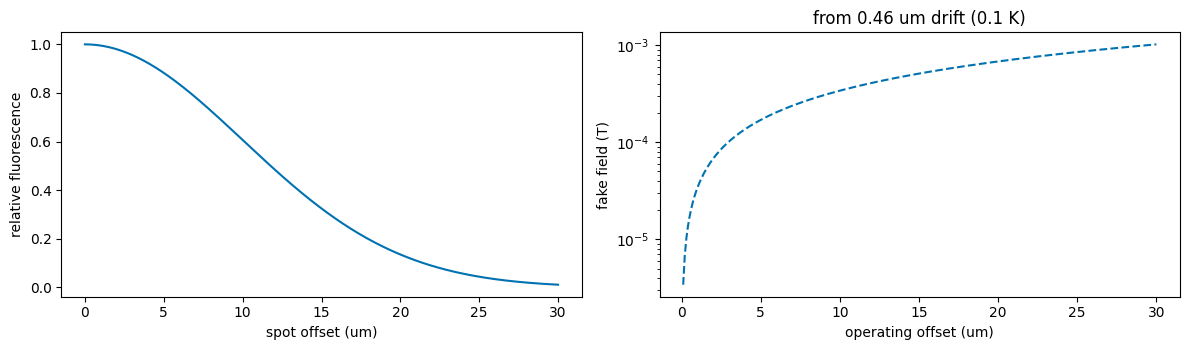

Figure description: left, fluorescence falls as a Gaussian when the pump spot moves off the diamond. Right (dashed, log axis), the fake magnetic field produced by a 0.1 K thermal pointing drift grows linearly with the operating offset and vanishes when the spot is centered.


In [11]:
w = 20e-6
offs = np.linspace(0, 30e-6, 300)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(offs*1e6, nv.fluorescence_vs_offset(offs, w)); ax[0].set_xlabel("spot offset (um)"); ax[0].set_ylabel("relative fluorescence")
jit = nv.thermal_spot_drift(0.1, 0.02, L, d)
fake = nv.false_field_from_pointing(offs, jit, w, 8e6, 0.03)
ax[1].semilogy(offs[1:]*1e6, fake[1:], ls="--"); ax[1].set_xlabel("operating offset (um)"); ax[1].set_ylabel("fake field (T)")
ax[1].set_title(f"from {jit*1e6:.2f} um drift (0.1 K)"); plt.tight_layout(); plt.show()
print("Figure description: left, fluorescence falls as a Gaussian when the pump spot moves off the diamond. "
      "Right (dashed, log axis), the fake magnetic field produced by a 0.1 K thermal pointing drift grows "
      "linearly with the operating offset and vanishes when the spot is centered.")

Engineering lessons:
* **center the spot**: first-order sensitivity to pointing vanishes at zero offset;
* **use materials with matched expansion** (or a short screw) in the mount;
* **normalize** by a reference photodiode that sees the same laser.

A real setup does all three. The op-amp front end is where that normalization happens.

## 5. The op-amp: photodiode transimpedance amplifier

The red fluorescence lands on a photodiode, which outputs a current. An op-amp with feedback
$R_f\parallel C_f$ turns that current into a voltage. Write KCL at the inverting node, including
the photodiode capacitance $C_d$, and model the op-amp as a single pole $A(s)=\omega_t/s$. SymPy
solves for $V_o/I$:

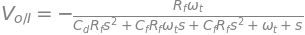

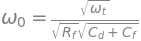

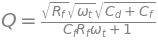

In [12]:
Ht, w0, Q = nv.tia_closed_loop_symbolic()
display(sp.Eq(sp.Symbol("V_o/I"), Ht), sp.Eq(sp.Symbol("omega_0"), w0), sp.Eq(sp.Symbol("Q"), Q))

It's a second-order system. Without $C_f$, $Q$ grows with $R_f$ and the amplifier rings or
oscillates. Choosing $C_f$ so that $Q=1/\sqrt2$ (Butterworth, maximally flat) gives the exact
condition:

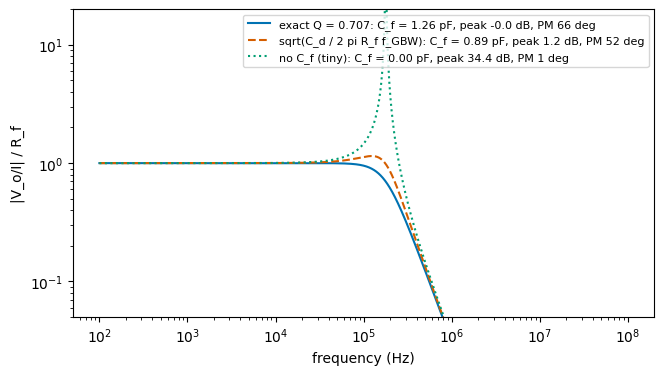

Figure description: closed-loop transimpedance versus frequency. The exact C_f (solid) is flat with no peak; the common approximate formula (dashed) peaks by about 1.2 dB; with almost no C_f (dotted) a tall resonant peak appears before roll-off.


In [13]:
cf_sym = nv.tia_flat_cf_symbolic()
display(sp.Eq(sp.Symbol("C_f (exact, Q = 1/sqrt2)"), cf_sym[0]))
Rf, Cd, fg = 1e6, 50e-12, 10e6
cf_exact = nv.tia_flat_cf(Rf, Cd, fg); cf_approx = tia.compensation_capacitor(Rf, Cd, fg)
f = np.logspace(2, 8, 20000)
fig, ax = plt.subplots(figsize=(7.5, 4))
for (name, cf), ls in zip([("exact Q = 0.707", cf_exact), ("sqrt(C_d / 2 pi R_f f_GBW)", cf_approx), ("no C_f (tiny)", 1e-15)], ["-", "--", ":"]):
    Hm = nv.tia_response(f, Rf, cf, Cd, fg)
    ax.loglog(f, Hm/Rf, ls=ls, label=f"{name}: C_f = {cf*1e12:.2f} pF, peak {20*np.log10(Hm.max()/Rf):.1f} dB, PM {tia.phase_margin(Rf, Cd, cf, fg):.0f} deg")
ax.set_ylim(0.05, 20); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("|V_o/I| / R_f"); ax.legend(fontsize=8); plt.show()
print("Figure description: closed-loop transimpedance versus frequency. The exact C_f (solid) is flat with no peak; "
      "the common approximate formula (dashed) peaks by about 1.2 dB; with almost no C_f (dotted) a tall resonant "
      "peak appears before roll-off.")

**A finding about the repo's own code.** `dgs.transimpedance_amplifier.compensation_capacitor`
documents $C_f=\sqrt{C_d/(2\pi R_ff_{GBW})}$ as maximally flat. The exact SymPy root is about
$\sqrt2$ times larger. The approximate formula gives about 52° of phase margin and 1.2 dB of
peaking, which is a classic "45°-ish" design, not Butterworth (≈ 65.5°). The module's
`closed_loop_bandwidth` does match the exact flat design. Use the exact root when flatness matters.

### Noise: when is the readout shot-noise limited?

The Johnson current noise of $R_f$, $\sqrt{4kT/R_f}$, falls below the photocurrent's shot noise,
$\sqrt{2qI}$, once $IR_f>2kT/q\approx52$ mV. The noise currents below come from the existing
`transimpedance_amplifier` module:

In [14]:
P = 10e-6                              # 10 uW of red fluorescence collected
b = nv.readout_noise_budget(P, 700, Rf, Cd, 1e4)
print(f"photocurrent {b['photocurrent']*1e6:.2f} uA;  R_f for shot-noise limit > {nv.shot_noise_limited_rf(b['photocurrent'])/1e3:.1f} kOhm (using {Rf/1e6:.0f} MOhm)")
for k in ("shot", "thermal", "amplifier"):
    print(f"  {k:9s} noise current in 10 kHz: {b[k]*1e12:8.3f} pA")
I = b["photocurrent"]; R_photons = I / nv.Q_E          # detected photoelectrons per second
print(f"\n=> detected photon rate ~ {R_photons:.2e}/s; with Gamma = 8 MHz, C = 0.03: eta = {nv.sensitivity(8e6, 0.03, R_photons):.2e} T/sqrt(Hz)")

photocurrent 4.52 uA;  R_f for shot-noise limit > 11.4 kOhm (using 1 MOhm)
  shot      noise current in 10 kHz:  120.304 pA
  thermal   noise current in 10 kHz:   12.872 pA
  amplifier noise current in 10 kHz:    0.907 pA

=> detected photon rate ~ 2.82e+13/s; with Gamma = 8 MHz, C = 0.03: eta = 1.38e-09 T/sqrt(Hz)


Shot noise dominates, so the electronics don't limit the sensor: the **quantum** noise of the
light does. That's the design goal of every quantum-sensor front end, and the same
noise-budget logic as the optical receivers elsewhere in this repo.

## 6. Summary

| block | key result |
|---|---|
| spin | lines at $D\pm\gamma_eB_\parallel$, $\gamma_e=28$ GHz/T |
| sensitivity | $\eta=4\Gamma/(3\sqrt3\gamma_eC\sqrt R)$ |
| vector | 4 axes give $|\mathbf B\cdot\hat n_k|$; labels need a bias field (symmetry ambiguity) |
| mounts | spot shift $2dp/L$ per turn; thermal tilt $\Delta\alpha\,h\,\Delta T/L$; center the spot |
| op-amp | exact Butterworth $C_f=\sqrt{2C_dR_f\omega_t-1}/(R_f\omega_t)$; shot-noise limited when $IR_f>2kT/q$ |

**Connections to the rest of the repo:**
* The NV's microwave transitions are qubit rotations (`polarization_qubit`, `quantum_gyroscope`).
* The fluorescence readout is a $Z$ measurement.
* Fitting dips is a cousin of the atom-interferometer fringe retrieval in `gps_denied_navigation`.

*Synthetic data; civilian education.*